# DSC 411/511 Project
# Notebook 13: RQ11 (new): Which Claims Look Wrong or Unusual? Rules vs Isolation Forest vs Local Outlier Factor

**Class topics:** Lecture 13 (outliers and anomaly detection: global vs contextual anomalies, Isolation Forest),
Lecture 06 (k nearest neighbours, the base of the Local Outlier Factor), Lecture 03 (noise, placeholder codes, unit
errors), Lecture 07 (evaluation: precision, recall, ROC-AUC, grouped cross-validation).

---

**How this question was derived.** Notebook 01 (Section 5.3) ran one Isolation Forest on all claims and found that its
1% "anomalies" were mostly large commercial and condo policies: rare, but real. Notebook 11 (RQ9) found **data errors**
in the depth field (placeholder 99, feet vs inches, heaps at 12 and 24, as described by Wing et al. 2020). Those two
findings raise a practical question for anyone who uses the claims file:

> **RQ11. Which claims look wrong or unusual? Do two unsupervised anomaly detectors (Isolation Forest and Local Outlier
> Factor, with and without "within-event" features) find the same claims as simple rule-based checks, and are their
> flags stable?**

There is no list of "true errors". So we build **rule flags** from the data dictionary and published artefacts, and use
them as an imperfect yardstick for the unsupervised models.

---
# Section 0: Setup

In [1]:
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
notebook_start = time.time()
claims = load_clean_claims()
print(f'Cleaned claims 2020-2025: {len(claims):,}')

Cleaned claims 2020-2025: 253,124


---
# Section 1: Data Used and Excluded

**Rows:** claims with building damage above \$0 and a building value above \$0 (an adjusted building claim), so that every
model feature exists. Claims without an adjusted building value (mostly unpaid, notebook 11) cannot be scored this way.

| Use | Columns |
|---|---|
| **model features** | log damage, log building value, damage / value, log coverage, log building payment, payment / damage, log contents damage, building age, log deductible |
| **within-event features** | log damage and damage / value as z-scores inside the claim's event (`event_group`) |
| **rule checks only** (never model features) | `waterDepth`, `interiorWaterDepth`, `netBuildingPaymentAmount`, `contentsPropertyValue` |

Depth columns are kept **out** of the models on purpose: then the depth rules are an **independent** check of the models.

In [2]:
data = claims[(claims['buildingDamageAmount'] > 0) & (claims['buildingPropertyValue'] > 0)].copy().reset_index(drop=True)
data['log_damage'] = np.log1p(data['buildingDamageAmount'])
data['log_building_value'] = np.log1p(data['buildingPropertyValue'])
data['log_damage_to_value'] = np.log1p((data['buildingDamageAmount'] / data['buildingPropertyValue']).clip(upper=5))
data['log_paid'] = np.log1p(data['amountPaidOnBuildingClaim'].clip(lower=0))
data['paid_to_damage'] = (data['amountPaidOnBuildingClaim'] / data['buildingDamageAmount']).clip(0, 5)
data['log_contents_damage'] = np.log1p(data['contentsDamageAmount'].fillna(0).clip(lower=0))
data['building_age'] = data['building_age_at_loss'].fillna(data['building_age_at_loss'].median())
data['log_deductible'] = np.log(data['building_deductible_usd'])
for column in ['log_damage', 'log_damage_to_value']:
    event_mean = data.groupby('event_group')[column].transform('mean')
    event_sd = data.groupby('event_group')[column].transform('std').replace(0, np.nan)
    data[f'{column}_within_event_z'] = ((data[column] - event_mean) / event_sd).fillna(0)
GLOBAL_FEATURES = ['log_damage', 'log_building_value', 'log_damage_to_value', 'log_building_coverage', 'log_paid', 'paid_to_damage',
                   'log_contents_damage', 'building_age', 'log_deductible']
CONTEXT_EVENT_FEATURES = GLOBAL_FEATURES + ['log_damage_within_event_z', 'log_damage_to_value_within_event_z']
print(f'Claims scored: {len(data):,} ({len(data) / len(claims) * 100:.1f}% of all claims)')

Claims scored: 207,336 (81.9% of all claims)


---
# Section 2: Rule-Based Checks (step by step)

| Rule | Check | Why it is suspicious | Uses model columns? |
|---|---|---|---|
| R1 depth heaping | `waterDepth` is 12, 24, 36, ... | Wing et al. (2020): "anomalous numbers of claims ... with depths of 12 and 24 feet" (likely inches in a feet field) | no |
| R2 depth placeholder | `waterDepth` = 99 | a code, not a depth (notebook 11, Section 2.1) | no |
| R3 depth in the minority unit | `waterDepth` >= 6 and within 1 of `interiorWaterDepth` (inches) | most records are in feet (notebook 11); the dictionary says "in inches. Note: there are instances where measurements were provided in feet" | no |
| R4 damage > building value | `buildingDamageAmount` > `buildingPropertyValue` | damage to a building above its own value | **yes** |
| R5 negative net payment | `netBuildingPaymentAmount` < 0 | a recovery larger than the payment | no |
| R6 payment > coverage | `amountPaidOnBuildingClaim` > `totalBuildingInsuranceCoverage` | the policy limit should cap the payment | **yes** |
| R7 payment far above damage | payment > 1.5 x damage + \$1,000 | payment can include items outside `buildingDamageAmount` (notebook 01), but not this much | **yes** |
| R8 contents damage > contents value | `contentsDamageAmount` > `contentsPropertyValue` (both > 0) | damage above value | partly (contents damage) |

In [3]:
water_depth = data['waterDepth']
data['R1_depth_heaping_12_24'] = water_depth.isin([12, 24, 36, 48, 60, 72, 84, 96]).astype(int)
data['R2_depth_placeholder_99'] = (water_depth == 99).astype(int)
data['R3_depth_in_minority_unit'] = ((water_depth >= 6) & (water_depth != 99) & (data['interiorWaterDepth'] > 0)
                                     & (np.abs(water_depth - data['interiorWaterDepth']) <= 1)).astype(int)
data['R4_damage_above_value'] = (data['buildingDamageAmount'] > data['buildingPropertyValue']).astype(int)
data['R5_negative_net_payment'] = (data['netBuildingPaymentAmount'] < 0).astype(int)
data['R6_paid_above_coverage'] = (data['amountPaidOnBuildingClaim'] > data['totalBuildingInsuranceCoverage']).astype(int)
data['R7_paid_far_above_damage'] = (data['amountPaidOnBuildingClaim'] > 1.5 * data['buildingDamageAmount'] + 1000).astype(int)
data['R8_contents_damage_above_value'] = ((data['contentsPropertyValue'] > 0) & (data['contentsDamageAmount'] > data['contentsPropertyValue'])).astype(int)
RULES = [c for c in data.columns if c[:2] in {'R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8'} and c[2] == '_']
INDEPENDENT_RULES = ['R1_depth_heaping_12_24', 'R2_depth_placeholder_99', 'R3_depth_in_minority_unit', 'R5_negative_net_payment']
OVERLAPPING_RULES = ['R4_damage_above_value', 'R6_paid_above_coverage', 'R7_paid_far_above_damage', 'R8_contents_damage_above_value']
data['any_independent_rule'] = data[INDEPENDENT_RULES].max(axis=1)
data['any_overlapping_rule'] = data[OVERLAPPING_RULES].max(axis=1)
data['any_rule'] = data[RULES].max(axis=1)
rule_table = pd.DataFrame({'claims_flagged': data[RULES + ['any_independent_rule', 'any_overlapping_rule', 'any_rule']].sum(),
                           'share_%': data[RULES + ['any_independent_rule', 'any_overlapping_rule', 'any_rule']].mean() * 100}).round(3)
rule_table['uses_model_columns'] = ['no', 'no', 'no', 'yes', 'no', 'yes', 'yes', 'partly', '-', '-', '-']
rule_table.to_csv(TABLE_DIR / '13_rq11_rule_flags.csv')
print(rule_table.to_string())
print('\nHow often rules occur together (Jaccard overlap of the flagged sets):')
overlap = pd.DataFrame(index=RULES, columns=RULES, dtype=float)
for a in RULES:
    for b in RULES:
        union = ((data[a] == 1) | (data[b] == 1)).sum()
        overlap.loc[a, b] = ((data[a] == 1) & (data[b] == 1)).sum() / union if union else np.nan
print(overlap.round(2).to_string())

                                claims_flagged  share_% uses_model_columns
R1_depth_heaping_12_24                     481    0.232                 no
R2_depth_placeholder_99                   8100    3.907                 no
R3_depth_in_minority_unit                 2745    1.324                 no
R4_damage_above_value                     1543    0.744                yes
R5_negative_net_payment                      1    0.000                 no
R6_paid_above_coverage                       4    0.002                yes
R7_paid_far_above_damage                  1759    0.848                yes
R8_contents_damage_above_value             595    0.287             partly
any_independent_rule                     11033    5.321                  -
any_overlapping_rule                      3778    1.822                  -
any_rule                                 14301    6.897                  -

How often rules occur together (Jaccard overlap of the flagged sets):
                             

**How to read this.** 207,336 claims have damage > 0 and a building value, and 6.9% of them (14,301) break at least one rule.

- The depth rules hit most often: the placeholder 99 (R2) is on 8,100 claims (3.9%). A depth in the minority unit (inches, R3) is on 2,745 claims (1.3%). Heaping at 12/24/36 (R1) is on 481 claims (0.23%).
- Damage above the building value (R4) is on 1,543 claims (0.74%), and payment far above the damage (R7) on 1,759 (0.85%).
- The payment rules almost never fire: there is 1 negative net payment (R5) and 4 payments above the coverage (R6). FEMA seems to clean these fields before release.
- The rules rarely overlap (every Jaccard value is 0.10 or less). They catch different problems, so no single detector can be expected to find all of them.

---
# Section 3: Two Unsupervised Detectors (step by step)

**3.1 Isolation Forest (Liu, Ting & Zhou 2008).** Anomalies are "few and different", so they are **easy to isolate**.
1. Build a random tree: pick a random feature and a random split value between its min and max; repeat on each side
   until every point is alone (or a depth limit is reached). Each tree uses a random subsample of 256 points.
2. The **path length** $h(x)$ is the number of splits needed to isolate $x$. Anomalies get short paths.
3. Average over many trees: $E[h(x)]$. Normalise by $c(n)$, the average path length of an unsuccessful search in a
   binary tree of $n$ points: score $s(x) = 2^{-E[h(x)]/c(n)}$. Scores near 1 are anomalies; near 0.5 are normal.

**3.2 Local Outlier Factor (Breunig et al. 2000).** An anomaly sits in a region that is **less dense than its
neighbours' regions** (a local, not a global, view).
1. $k$-distance of a point $p$: the distance to its $k$-th nearest neighbour (Lecture 06).
2. Reachability distance of $p$ from $o$: $\max(k\text{-distance}(o), d(p, o))$, which smooths very small distances.
3. Local reachability density: $\text{lrd}(p) = 1 / \text{mean}_{o \in N_k(p)}\,\text{reach-dist}(p, o)$.
4. $\text{LOF}(p) = \text{mean}_{o \in N_k(p)}\,\text{lrd}(o) / \text{lrd}(p)$. About 1 = as dense as its neighbours; much
   larger than 1 = an outlier.
LOF needs distances, so features are standardised first (fitted on the training rows). It is slow on 200,000 claims,
so the reference set is a 30,000-claim random sample of the training years (`novelty=True`), and every claim is then
scored against it.

**Setup.** Both models are fitted on **2020-2023** and score every claim; the 2024-2025 claims are a test set. We
flag the **top 1%** of scores in each year group. Each detector is run with the global features and with the global +
within-event features (a claim can be normal nationally but unusual for its own storm: a **contextual** anomaly).

In [4]:
train_mask = data['loss_year'].isin(TRAIN_YEARS).values
test_mask = data['loss_year'].isin(TEST_YEARS).values
LOF_SAMPLE = 30_000
TOP_SHARE = 0.01


def anomaly_scores(model_name, features, fit_rows, score_rows, seed=SEED):
    """Higher score = more anomalous."""
    scaler = StandardScaler().fit(fit_rows[features])
    if model_name == 'Isolation Forest':
        model = IsolationForest(n_estimators=200, max_samples=256, random_state=seed, n_jobs=-1).fit(scaler.transform(fit_rows[features]))
        return -model.score_samples(scaler.transform(score_rows[features]))
    sample = fit_rows.sample(min(LOF_SAMPLE, len(fit_rows)), random_state=seed)
    model = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1).fit(scaler.transform(sample[features]))
    return -model.score_samples(scaler.transform(score_rows[features]))


def top_share_flag(scores, mask_by_group):
    """Flag the top 1% of scores separately inside each group (train years, test years)."""
    flags = np.zeros(len(scores), dtype=int)
    for mask in mask_by_group:
        threshold = np.quantile(scores[mask], 1 - TOP_SHARE)
        flags[mask & (scores >= threshold)] = 1
    return flags


DETECTORS = {'Isolation Forest (global)': ('Isolation Forest', GLOBAL_FEATURES),
             'Isolation Forest (+ within-event)': ('Isolation Forest', CONTEXT_EVENT_FEATURES),
             'LOF (global)': ('LOF', GLOBAL_FEATURES),
             'LOF (+ within-event)': ('LOF', CONTEXT_EVENT_FEATURES)}
start = time.time()
train_rows = data[train_mask]
for detector_name, (model_name, features) in DETECTORS.items():
    data[f'score_{detector_name}'] = anomaly_scores(model_name, features, train_rows, data)
    data[f'flag_{detector_name}'] = top_share_flag(data[f'score_{detector_name}'].values, [train_mask, test_mask])
print(f'Four detectors fitted and all {len(data):,} claims scored in {time.time() - start:.0f} s')

Four detectors fitted and all 207,336 claims scored in 13 s


---
# Section 4: Do the Detectors Find the Rule Flags? (precision, recall, ROC-AUC)

For the **top 1%** flagged claims of each detector:
- **precision** = share of flagged claims that break a rule; **lift** = precision / the rule's base rate;
- **recall** = share of rule-breaking claims that are flagged (at most 1% / base rate when the rule is common);
- **ROC-AUC** of the score: does a higher anomaly score go with breaking the rule, over all claims?

Read the **independent** rules (depth, net payment) as the fair test, because the models never saw those columns. The
**overlapping** rules share columns with the features, so a high score there is partly circular (Section 8).

In [5]:
validation_rows = []
for detector_name in DETECTORS:
    flags = data[f'flag_{detector_name}'].values
    scores = data[f'score_{detector_name}'].values
    for rule in RULES + ['any_independent_rule', 'any_overlapping_rule']:
        truth = data[rule].values
        if truth.sum() == 0:
            continue
        precision = truth[flags == 1].mean()
        validation_rows.append({'detector': detector_name, 'rule': rule, 'rule_base_rate_%': truth.mean() * 100, 'precision_top1%_%': precision * 100,
                                'lift': precision / truth.mean(), 'recall_%': truth[flags == 1].sum() / truth.sum() * 100,
                                'ROC_AUC': roc_auc_score(truth, scores) if truth.sum() >= 5 else np.nan})
validation_table = pd.DataFrame(validation_rows).round(3)
validation_table.to_csv(TABLE_DIR / '13_rq11_detectors_vs_rules.csv', index=False)
summary_view = validation_table[validation_table['rule'].isin(['any_independent_rule', 'any_overlapping_rule'] + INDEPENDENT_RULES[:3] + ['R4_damage_above_value'])]
print(summary_view.pivot(index='rule', columns='detector', values='ROC_AUC').round(3).to_string())
print()
print(summary_view.pivot(index='rule', columns='detector', values='lift').round(2).to_string())

detector                   Isolation Forest (+ within-event)  Isolation Forest (global)  LOF (+ within-event)  LOF (global)
rule                                                                                                                       
R1_depth_heaping_12_24                                 0.650                      0.653                 0.555         0.554
R2_depth_placeholder_99                                0.466                      0.475                 0.525         0.536
R3_depth_in_minority_unit                              0.566                      0.590                 0.512         0.511
R4_damage_above_value                                  0.942                      0.894                 0.773         0.782
any_independent_rule                                   0.495                      0.508                 0.524         0.532
any_overlapping_rule                                   0.845                      0.851                 0.694         0.703

detecto

**How to read this.** These tables show how well each detector finds the rule-flagged claims.

- **Independent rules** (depth heaping, 99, units, negative payment) use columns the detectors never see. Here all four detectors are close to chance: ROC-AUC is 0.50-0.53, and the top-1% lift is only 1.6-2.3. Isolation Forest and LOF do **not** find depth-recording errors on their own.
- **Overlapping rules** (damage > value, paid > coverage, paid >> damage, contents) use columns the detectors do see, so finding them is partly circular. Isolation Forest ranks them well: ROC-AUC is 0.85 for the global model and 0.85 with event features, against about 0.70 for LOF. In the top 1% the picture changes: LOF (global) has the highest lift (12.7, precision 23%, against a 1.8% base rate), and the within-event Isolation Forest is close (11.9).
- So the two methods work differently. Isolation Forest is better over the whole ranking, and LOF is a little better at the very top. Adding within-event z-scores roughly doubles the Isolation Forest's top-1% lift (5.8 -> 11.9) but does not change its AUC.

---
# Section 5: Event-Grouped Cross-Validation on 2020-2023 and the 2024-2025 Test with Event-Block Bootstrap

**CV.** 5 folds grouped by event: fit each detector on four folds, score the held-out events, and compute the ROC-AUC
against the independent and the overlapping rule flags. We report the mean **and** the spread over folds.

**Test.** The detectors fitted on 2020-2023 score the 2024-2025 claims. We compare each detector with the global
Isolation Forest using a 95% event-block bootstrap of the ROC-AUC difference (`event_block_bootstrap`, 500 repeats).

In [6]:
start = time.time()
train_frame = data[train_mask].reset_index(drop=True)
cv_rows = []
for fold, (fit_index, validation_index) in enumerate(GroupKFold(n_splits=5).split(train_frame, groups=train_frame['event_group'])):
    fit_rows, held_out = train_frame.iloc[fit_index], train_frame.iloc[validation_index]
    for detector_name, (model_name, features) in DETECTORS.items():
        scores = anomaly_scores(model_name, features, fit_rows, held_out)
        for truth_name in ['any_independent_rule', 'any_overlapping_rule']:
            cv_rows.append({'detector': detector_name, 'truth': truth_name, 'fold': fold, 'ROC_AUC': roc_auc_score(held_out[truth_name], scores)})
cv_table = pd.DataFrame(cv_rows).groupby(['truth', 'detector'])['ROC_AUC'].agg(['mean', 'std', 'min', 'max']).round(4)
cv_table.to_csv(TABLE_DIR / '13_rq11_event_grouped_cv.csv')
print(f'Event-grouped 5-fold CV ROC-AUC on 2020-2023 ({time.time() - start:.0f} s):')
print(cv_table.to_string())

Event-grouped 5-fold CV ROC-AUC on 2020-2023 (14 s):
                                                          mean     std     min     max
truth                detector                                                         
any_independent_rule Isolation Forest (+ within-event)  0.4946  0.0271  0.4680  0.5325
                     Isolation Forest (global)          0.4973  0.0294  0.4658  0.5403
                     LOF (+ within-event)               0.5186  0.0244  0.4818  0.5474
                     LOF (global)                       0.5260  0.0185  0.5036  0.5483
any_overlapping_rule Isolation Forest (+ within-event)  0.8574  0.0222  0.8336  0.8902
                     Isolation Forest (global)          0.8636  0.0222  0.8267  0.8838
                     LOF (+ within-event)               0.6448  0.0717  0.5635  0.7086
                     LOF (global)                       0.6693  0.0622  0.6028  0.7462


In [7]:
test_frame = data[test_mask].reset_index(drop=True)
test_tables = []
for truth_name in ['any_independent_rule', 'any_overlapping_rule']:
    table = event_block_bootstrap(test_frame, truth_name, {name: f'score_{name}' for name in DETECTORS}, {'ROC_AUC': roc_auc_score},
                                  baseline='Isolation Forest (global)', n_repeats=500)
    table.insert(0, 'truth', truth_name)
    test_tables.append(table)
test_table = pd.concat(test_tables).round(4).rename(columns={'gain_vs_baseline': 'difference_vs_IF_global'})
test_table.to_csv(TABLE_DIR / '13_rq11_test_years_auc.csv', index=False)
print('Test years 2024-2025, ROC-AUC against the rule flags (difference vs the global Isolation Forest, 95% event CI):')
print(test_table.drop(columns=['metric']).to_string(index=False))

Test years 2024-2025, ROC-AUC against the rule flags (difference vs the global Isolation Forest, 95% event CI):
               truth                             model  value  difference_vs_IF_global  ci_95_low  ci_95_high  share_of_repeats_with_gain_%  events  valid_repeats
any_independent_rule         Isolation Forest (global) 0.4945                      NaN        NaN         NaN                           NaN      26            500
any_independent_rule Isolation Forest (+ within-event) 0.4725                  -0.0220    -0.0331      0.0005                           2.8      26            500
any_independent_rule                      LOF (global) 0.5309                   0.0363     0.0181      0.0439                         100.0      26            500
any_independent_rule              LOF (+ within-event) 0.5155                   0.0209     0.0121      0.0355                         100.0      26            500
any_overlapping_rule         Isolation Forest (global) 0.8287            

**How to read this.** The event-grouped CV on 2020-2023 tells the same story with a spread.

- Isolation Forest (global) has CV ROC-AUC 0.864 +/- 0.022 for the overlapping rules, against 0.669 +/- 0.062 for LOF (global).
- For the independent rules every detector is about 0.50 +/- 0.03.
- On the test years 2024-2025, the event-block bootstrap gives LOF (global) minus IF (global) = -0.093 [-0.211, -0.056] on the overlapping rules: LOF is clearly worse. On the independent rules LOF is slightly better, +0.036 [+0.018, +0.044]. That gain is significant but tiny: an AUC of 0.53 is still close to chance.
- Adding event features to the Isolation Forest does not change the AUC (-0.001 [-0.016, +0.004]).

---
# Section 6: Stability: Seeds, Samples, and Agreement Between Detectors

A flag is only useful if it does not change with a random seed. For the Isolation Forest we refit with 5 seeds (random
trees change); for LOF we use 5 different 30,000-claim reference samples. We compare the **top-1% sets** with the
**Jaccard index** = |A and B| / |A or B| (1 = identical sets). We also compare the detectors with each other and with
the notebook 01 Isolation Forest flag.

In [8]:
start = time.time()
SEEDS = [42, 7, 123, 2024, 99]
stability_rows = []
for detector_name in ['Isolation Forest (global)', 'LOF (global)']:
    model_name, features = DETECTORS[detector_name]
    flag_sets = []
    for seed in SEEDS:
        scores = anomaly_scores(model_name, features, train_rows, data, seed=seed)
        flag_sets.append(set(np.where(top_share_flag(scores, [train_mask, test_mask]) == 1)[0]))
    jaccards = [len(flag_sets[i] & flag_sets[j]) / len(flag_sets[i] | flag_sets[j]) for i in range(len(SEEDS)) for j in range(i + 1, len(SEEDS))]
    stability_rows.append({'detector': detector_name, 'what changes': 'random trees' if model_name == 'Isolation Forest' else 'reference sample',
                           'mean_Jaccard_top1%': np.mean(jaccards), 'min_Jaccard': np.min(jaccards), 'max_Jaccard': np.max(jaccards)})
stability_table = pd.DataFrame(stability_rows).round(3)
stability_table.to_csv(TABLE_DIR / '13_rq11_seed_stability.csv', index=False)
print(f'({time.time() - start:.0f} s)'); print(stability_table.to_string(index=False))

flag_sets = {name: set(np.where(data[f'flag_{name}'] == 1)[0]) for name in DETECTORS}
flag_sets['rule: any independent'] = set(np.where(data['any_independent_rule'] == 1)[0])
flag_sets['rule: any overlapping'] = set(np.where(data['any_overlapping_rule'] == 1)[0])
flag_sets['notebook 01 Isolation Forest'] = set(np.where(data['flag_isolation_forest_anomaly'] == 1)[0])
agreement = pd.DataFrame(index=list(flag_sets), columns=list(flag_sets), dtype=float)
for a in flag_sets:
    for b in flag_sets:
        agreement.loc[a, b] = len(flag_sets[a] & flag_sets[b]) / len(flag_sets[a] | flag_sets[b]) if flag_sets[a] | flag_sets[b] else np.nan
agreement.round(3).to_csv(TABLE_DIR / '13_rq11_agreement_jaccard.csv')
print('\nJaccard agreement between flag sets:'); print(agreement.round(3).to_string())

(27 s)
                 detector     what changes  mean_Jaccard_top1%  min_Jaccard  max_Jaccard
Isolation Forest (global)     random trees               0.597        0.432        0.697
             LOF (global) reference sample               0.678        0.665        0.701

Jaccard agreement between flag sets:
                                   Isolation Forest (global)  Isolation Forest (+ within-event)  LOF (global)  LOF (+ within-event)  rule: any independent  rule: any overlapping  notebook 01 Isolation Forest
Isolation Forest (global)                              1.000                              0.392         0.063                 0.072                  0.013                  0.039                         0.220
Isolation Forest (+ within-event)                      0.392                              1.000         0.060                 0.061                  0.019                  0.083                         0.243
LOF (global)                                           0.063    

**How to read this.** We ask whether the top-1% sets stay the same when the random parts change.

- When only the random seed changes, the Isolation Forest top-1% sets share on average 60% of their claims (Jaccard 0.597, range 0.43-0.70). LOF with a new reference sample is a little more stable (0.678).
- The Isolation Forest and LOF flag almost completely **different** claims (Jaccard 0.063).
- Our global Isolation Forest agrees only partly with the notebook 01 Isolation Forest (0.22), which used other columns and all rows.
- So a claim's flag depends a lot on which detector you use and on its seed. A flag is a reason to look at a claim, not a finding.

---
# Section 7: What Do the Flagged Claims Look Like?

Median values:
                                all scored claims  top 1%: Isolation Forest (global)  top 1%: LOF (global)  top 1%: LOF (+ within-event)
buildingDamageAmount                      37140.0                            26962.0               44535.0                       32625.0
buildingPropertyValue                    227050.0                          1580499.0              193661.0                      199144.0
totalBuildingInsuranceCoverage           250000.0                           500000.0              250000.0                      250000.0
amountPaidOnBuildingClaim                 34395.0                                0.0               28035.0                       17525.0
contentsDamageAmount                       3940.0                             3257.0                5830.0                        5729.0
building_age                                 50.0                               47.0                  47.0                          48.0

Occupancy mix (%):
      

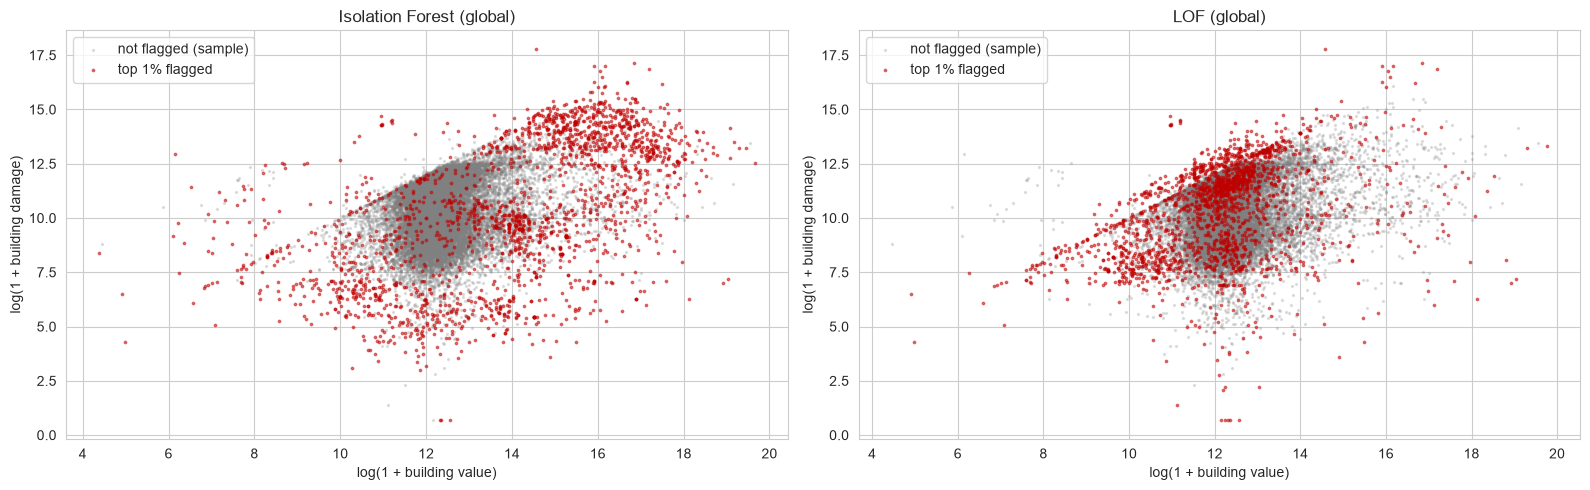

In [9]:
profile_columns = ['buildingDamageAmount', 'buildingPropertyValue', 'totalBuildingInsuranceCoverage', 'amountPaidOnBuildingClaim',
                   'contentsDamageAmount', 'building_age']
profile = {'all scored claims': data[profile_columns].median()}
for name in ['Isolation Forest (global)', 'LOF (global)', 'LOF (+ within-event)']:
    profile[f'top 1%: {name}'] = data.loc[data[f'flag_{name}'] == 1, profile_columns].median()
profile_table = pd.DataFrame(profile).round(0)
occupancy_mix = pd.DataFrame({name: data.loc[data[f'flag_{name}'] == 1, 'occupancy_group'].value_counts(normalize=True) * 100
                              for name in ['Isolation Forest (global)', 'LOF (global)']})
occupancy_mix['all scored claims'] = data['occupancy_group'].value_counts(normalize=True) * 100
profile_table.to_csv(TABLE_DIR / '13_rq11_flag_profile.csv')
occupancy_mix.round(1).to_csv(TABLE_DIR / '13_rq11_flag_occupancy_mix.csv')
print('Median values:'); print(profile_table.to_string())
print('\nOccupancy mix (%):'); print(occupancy_mix.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sample_plot = data.sample(20_000, random_state=SEED)
for ax, name in zip(axes, ['Isolation Forest (global)', 'LOF (global)']):
    normal = sample_plot[sample_plot[f'flag_{name}'] == 0]
    flagged = data[data[f'flag_{name}'] == 1]
    ax.scatter(normal['log_building_value'], normal['log_damage'], s=2, alpha=0.2, color='grey', label='not flagged (sample)')
    ax.scatter(flagged['log_building_value'], flagged['log_damage'], s=3, alpha=0.5, color='#C00000', label='top 1% flagged')
    ax.set_xlabel('log(1 + building value)'); ax.set_ylabel('log(1 + building damage)'); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.savefig(FIGURE_DIR / '13_rq11_flagged_claims.png', dpi=120); plt.show()

**How to read this.** The global Isolation Forest mostly flags **unusual kinds of claims**, not errors. Its top 1% has:

- a median building value of \$1.58 million (against \$227,050 for all claims) and a median coverage of \$500,000;
- a median payment of \$0;
- 31.8% condo associations and 31.3% non-residential buildings (against 4.3% and 7.0% of all claims).

LOF flags look more like ordinary claims: 52% single family homes, with medians close to the full data. LOF finds claims that are odd *for their neighbourhood in feature space*. That is why the two methods disagree.

---
# Section 8: Leakage and Circularity

- **This is an audit of records after the fact.** The features include the adjuster's damage and the payment. That is
  intended: the question is "does this finished record look wrong?", not a prediction at claim time.
- **Circular validation.** Rules R4, R6, R7 (and partly R8) are built from columns that are also model features. A
  detector can "find" them simply because they are extreme values of its own inputs. Only the independent rules (R1-R3,
  R5) test whether the detectors find errors they were not shown; R5 has very few cases, so the depth rules carry that test.
- **Rules are not the truth either.** R7 can be a legitimate payment for items outside `buildingDamageAmount`; a depth
  of 12 can be a real 12 ft flood. Precision against rules is a yardstick, not an error rate.
- **The fitted models never see 2024-2025** (fit on 2020-2023), so the test-year results show how the detectors carry
  over to new storms.

---
## The numbers behind the answer

In [10]:
def validation_value(detector, rule, column):
    return validation_table[(validation_table['detector'] == detector) & (validation_table['rule'] == rule)].iloc[0][column]


def test_text(truth, detector):
    row = test_table[(test_table['truth'] == truth) & (test_table['model'] == detector)].iloc[0]
    if pd.isna(row['difference_vs_IF_global']):
        return f"{row['value']:.3f}"
    return f"{row['value']:.3f} (vs IF global {row['difference_vs_IF_global']:+.3f} [{row['ci_95_low']:+.3f}, {row['ci_95_high']:+.3f}])"


rows = [
    ('claims scored (damage > 0 and building value > 0)', len(data), 'Section 1'),
    ('R1 depth heaping 12/24/...: claims (%)', f"{int(rule_table.loc['R1_depth_heaping_12_24', 'claims_flagged']):,} ({rule_table.loc['R1_depth_heaping_12_24', 'share_%']:.2f}%)", '13_rq11_rule_flags'),
    ('R2 depth placeholder 99: claims (%)', f"{int(rule_table.loc['R2_depth_placeholder_99', 'claims_flagged']):,} ({rule_table.loc['R2_depth_placeholder_99', 'share_%']:.2f}%)", '13_rq11_rule_flags'),
    ('R3 depth in minority unit (inches): claims (%)', f"{int(rule_table.loc['R3_depth_in_minority_unit', 'claims_flagged']):,} ({rule_table.loc['R3_depth_in_minority_unit', 'share_%']:.2f}%)", '13_rq11_rule_flags'),
    ('R4 damage > building value: claims (%)', f"{int(rule_table.loc['R4_damage_above_value', 'claims_flagged']):,} ({rule_table.loc['R4_damage_above_value', 'share_%']:.2f}%)", '13_rq11_rule_flags'),
    ('R5 negative net payment / R6 paid > coverage: claims', f"{int(rule_table.loc['R5_negative_net_payment', 'claims_flagged'])} / {int(rule_table.loc['R6_paid_above_coverage', 'claims_flagged'])}", '13_rq11_rule_flags'),
    ('R7 paid far above damage / R8 contents damage > value: claims (%)', f"{rule_table.loc['R7_paid_far_above_damage', 'share_%']:.2f}% / {rule_table.loc['R8_contents_damage_above_value', 'share_%']:.2f}%", '13_rq11_rule_flags'),
    ('any rule: claims (%)', f"{int(rule_table.loc['any_rule', 'claims_flagged']):,} ({rule_table.loc['any_rule', 'share_%']:.2f}%)", '13_rq11_rule_flags'),
]
for detector in DETECTORS:
    rows.append((f'{detector}: ROC-AUC independent / overlapping rules (all years)',
                 f"{validation_value(detector, 'any_independent_rule', 'ROC_AUC'):.3f} / {validation_value(detector, 'any_overlapping_rule', 'ROC_AUC'):.3f}", '13_rq11_detectors_vs_rules'))
    rows.append((f'{detector}: top-1% lift independent / overlapping rules',
                 f"{validation_value(detector, 'any_independent_rule', 'lift'):.2f} / {validation_value(detector, 'any_overlapping_rule', 'lift'):.2f}", '13_rq11_detectors_vs_rules'))
for detector in DETECTORS:
    rows.append((f'CV ROC-AUC {detector}: independent / overlapping (mean +/- SD)',
                 f"{cv_table.loc[('any_independent_rule', detector), 'mean']:.3f} +/- {cv_table.loc[('any_independent_rule', detector), 'std']:.3f} / "
                 f"{cv_table.loc[('any_overlapping_rule', detector), 'mean']:.3f} +/- {cv_table.loc[('any_overlapping_rule', detector), 'std']:.3f}", '13_rq11_event_grouped_cv'))
for detector in DETECTORS:
    rows.append((f'test ROC-AUC overlapping rules: {detector}', test_text('any_overlapping_rule', detector), '13_rq11_test_years_auc'))
    rows.append((f'test ROC-AUC independent rules: {detector}', test_text('any_independent_rule', detector), '13_rq11_test_years_auc'))
rows += [
    ('seed stability IF (mean Jaccard of top 1%)', stability_table.iloc[0]['mean_Jaccard_top1%'], '13_rq11_seed_stability'),
    ('sample stability LOF (mean Jaccard of top 1%)', stability_table.iloc[1]['mean_Jaccard_top1%'], '13_rq11_seed_stability'),
    ('agreement IF global vs LOF global (Jaccard)', agreement.loc['Isolation Forest (global)', 'LOF (global)'], '13_rq11_agreement_jaccard'),
    ('agreement IF global vs notebook 01 IF (Jaccard)', agreement.loc['Isolation Forest (global)', 'notebook 01 Isolation Forest'], '13_rq11_agreement_jaccard'),
    ('agreement LOF global vs LOF within-event (Jaccard)', agreement.loc['LOF (global)', 'LOF (+ within-event)'], '13_rq11_agreement_jaccard'),
]
answer_numbers = show_answer_numbers(rows, '13_rq11')
data[['id', 'loss_year', 'event_group'] + RULES + [f'flag_{name}' for name in DETECTORS]].to_parquet(TABLE_DIR / '13_rq11_claim_flags.parquet', index=False)
print(f'\nNotebook run time: {(time.time() - notebook_start) / 60:.1f} min')

                                                                              quantity                                        value                     source
                                     claims scored (damage > 0 and building value > 0)                                       207336                  Section 1
                                                R1 depth heaping 12/24/...: claims (%)                                  481 (0.23%)         13_rq11_rule_flags
                                                   R2 depth placeholder 99: claims (%)                                8,100 (3.91%)         13_rq11_rule_flags
                                        R3 depth in minority unit (inches): claims (%)                                2,745 (1.32%)         13_rq11_rule_flags
                                                R4 damage > building value: claims (%)                                1,543 (0.74%)         13_rq11_rule_flags
                                  R5 negative 

---
# Research Question -> Answer

**Research question (RQ11):** Can unsupervised outlier detection (Isolation Forest, LOF), with or without within-event features, find suspicious or erroneous NFIP claims? How well do its flags agree with simple, explainable rule checks?

**Answer (from the numbers above).**

1. **Simple rules find most data problems.** 6.9% of the scored claims break at least one rule. The largest groups are depth problems: 8,100 claims with the 99 placeholder, 2,745 with depth in inches instead of feet, and 481 heaped at 12/24/36. Payment errors are almost absent (1 negative net payment, 4 payments above coverage).
2. **Detectors do not find the depth errors.** Against the rules that use columns the detectors do not see, all four detectors are at chance level. Test ROC-AUC is 0.47-0.53, and CV gives 0.50 +/- 0.03.
3. **Detectors do find value-inconsistent claims, but partly by construction.** Against the overlapping rules (damage > value and similar), the Isolation Forest reaches test ROC-AUC 0.829, against 0.736 for LOF (difference -0.093 [-0.211, -0.056]). In the top 1%, LOF (global) and the within-event Isolation Forest have a lift of about 12 (precision about 22%).
4. **Flags are unstable and depend on the method.** Changing the seed keeps only about 60% of the Isolation Forest top 1% (Jaccard 0.60). Isolation Forest and LOF share 6% of their flags, and our Isolation Forest shares 22% with notebook 01's.
5. **What the flags mean.** The global Isolation Forest mostly picks rare kinds of buildings: large condos and non-residential buildings with \$500k coverage and often \$0 paid. These are unusual, but not wrong.

**Bottom line:** for data quality, use the explainable rules first. Use Isolation Forest or LOF as a second, ranked list for human review, ideally with the within-event features. Do not use them as evidence of fraud or error. No label of true fraud exists in the public data, so every "precision" here only measures agreement with our rules.

**References for this notebook.**
- Liu, F. T., Ting, K. M. & Zhou, Z.-H. (2008). Isolation forest. *Proceedings of the 8th IEEE International Conference on Data Mining (ICDM)*, 413-422.
- Breunig, M. M., Kriegel, H.-P., Ng, R. T. & Sander, J. (2000). LOF: Identifying density-based local outliers. *Proceedings of the ACM SIGMOD International Conference on Management of Data*, 93-104.
- Chandola, V., Banerjee, A. & Kumar, V. (2009). Anomaly detection: A survey. *ACM Computing Surveys* 41(3), 15.
- Wing, O. E. J., Pinter, N., Bates, P. D. & Kousky, C. (2020). New insights into US flood vulnerability revealed from flood insurance big data. *Nature Communications* 11, 1444. https://doi.org/10.1038/s41467-020-15264-2
- FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3* (data dictionary: `waterDepth`, `interiorWaterDepth`, `amountPaidOnBuildingClaim`, `netBuildingPaymentAmount`). https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3